# CISC7204 Assignment 01 - Module 04 - Lab02 Model Development - Laptop Pricing


In [1]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib
matplotlib.use("Agg")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-Coursera/laptop_pricing_dataset_mod1.csv"
df = pd.read_csv(DATA_URL)
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])
pd.set_option("display.max_columns", None)
print("Dataset loaded successfully.")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully.
Shape: (238, 12)


  Manufacturer  Category     Screen  GPU  OS  CPU_core  Screen_Size_cm  \
0         Acer         4  IPS Panel    2   1         5          35.560   
1         Dell         3    Full HD    1   1         3          39.624   
2         Dell         3    Full HD    1   1         7          39.624   
3         Dell         4  IPS Panel    2   1         5          33.782   
4           HP         4    Full HD    2   1         7          39.624   

   CPU_frequency  RAM_GB  Storage_GB_SSD  Weight_kg  Price  
0            1.6       8             256       1.60    978  
1            2.0       4             256       2.20    634  
2            2.7       8             256       2.20    946  
3            1.6       8             128       1.22   1244  
4            1.8       8             256       1.91    837  

## Prepare A Clean Laptop Dataset

In [2]:
laptop_df = df.copy()

laptop_df["Screen_Size_cm"] = pd.to_numeric(laptop_df["Screen_Size_cm"], errors="coerce")
laptop_df["Weight_kg"] = pd.to_numeric(laptop_df["Weight_kg"], errors="coerce")

laptop_df["Weight_kg"].fillna(laptop_df["Weight_kg"].mean(), inplace=True)
laptop_df["Screen_Size_cm"].fillna(laptop_df["Screen_Size_cm"].mode()[0], inplace=True)

laptop_df["Screen_Size_inch"] = laptop_df["Screen_Size_cm"] / 2.54
laptop_df["Weight_pounds"] = laptop_df["Weight_kg"] * 2.205
laptop_df["CPU_frequency"] = laptop_df["CPU_frequency"] / laptop_df["CPU_frequency"].max()

bins = np.linspace(laptop_df["Price"].min(), laptop_df["Price"].max(), 4)
labels = ["Low", "Medium", "High"]
laptop_df["Price-binned"] = pd.cut(laptop_df["Price"], bins=bins, labels=labels, include_lowest=True)

screen_dummies = pd.get_dummies(laptop_df["Screen"], prefix="Screen")
laptop_df = pd.concat([laptop_df.drop(columns=["Screen"]), screen_dummies], axis=1)

print("Missing values after cleaning:")
print(laptop_df.isna().sum())
laptop_df.head()

Missing values after cleaning:
Manufacturer        0
Category            0
GPU                 0
OS                  0
CPU_core            0
Screen_Size_cm      0
CPU_frequency       0
RAM_GB              0
Storage_GB_SSD      0
Weight_kg           0
Price               0
Screen_Size_inch    0
Weight_pounds       0
Price-binned        0
Screen_Full HD      0
Screen_IPS Panel    0
dtype: int64


  Manufacturer  Category  GPU  OS  CPU_core  Screen_Size_cm  CPU_frequency  \
0         Acer         4    2   1         5          35.560       0.551724   
1         Dell         3    1   1         3          39.624       0.689655   
2         Dell         3    1   1         7          39.624       0.931034   
3         Dell         4    2   1         5          33.782       0.551724   
4           HP         4    2   1         7          39.624       0.620690   

   RAM_GB  Storage_GB_SSD  Weight_kg  Price  Screen_Size_inch  Weight_pounds  \
0       8             256       1.60    978              14.0        3.52800   
1       4             256       2.20    634              15.6        4.85100   
2       8             256       2.20    946              15.6        4.85100   
3       8             128       1.22   1244              13.3        2.69010   
4       8             256       1.91    837              15.6        4.21155   

  Price-binned  Screen_Full HD  Screen_IPS Panel  

## Task 1: Simple Linear Regression

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

X_simple = laptop_df[["CPU_frequency"]]
y = laptop_df["Price"]

simple_model = LinearRegression()
simple_model.fit(X_simple, y)
simple_pred = simple_model.predict(X_simple)

print("Intercept:", round(simple_model.intercept_, 3))
print("Coefficient:", round(simple_model.coef_[0], 3))
print("MSE:", round(mean_squared_error(y, simple_pred), 3))
print("R2:", round(r2_score(y, simple_pred), 3))

Intercept: 253.661
Coefficient: 1485.194
MSE: 284583.441
R2: 0.134


## Task 2: Multiple Linear Regression

In [4]:
features = ["CPU_frequency", "RAM_GB", "Storage_GB_SSD", "CPU_core", "OS", "GPU", "Category"]
X_multi = laptop_df[features]

multi_model = LinearRegression()
multi_model.fit(X_multi, y)
multi_pred = multi_model.predict(X_multi)

print("Features:", features)
print("MSE:", round(mean_squared_error(y, multi_pred), 3))
print("R2:", round(r2_score(y, multi_pred), 3))
pd.DataFrame({"Feature": features, "Coefficient": multi_model.coef_})

Features: ['CPU_frequency', 'RAM_GB', 'Storage_GB_SSD', 'CPU_core', 'OS', 'GPU', 'Category']
MSE: 161680.573
R2: 0.508


          Feature  Coefficient
0   CPU_frequency   961.283977
1          RAM_GB    86.808929
2  Storage_GB_SSD     0.394605
3        CPU_core    65.663398
4              OS  -427.445318
5             GPU    97.800087
6        Category   191.295466

## Task 3: Model Evaluation By Visualization

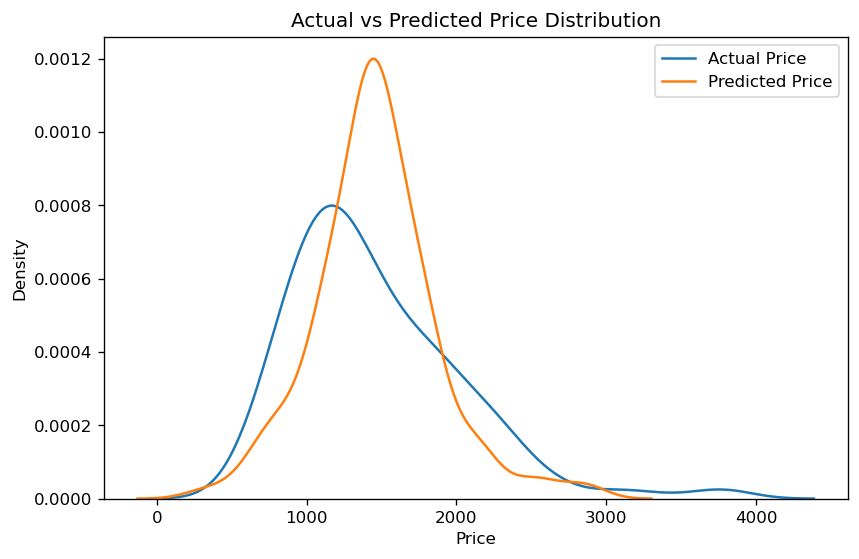

In [5]:
plt.figure(figsize=(8, 5))
sns.kdeplot(y, label="Actual Price", fill=False)
sns.kdeplot(multi_pred, label="Predicted Price", fill=False)
plt.title("Actual vs Predicted Price Distribution")
plt.xlabel("Price")
plt.legend()
plt.show()

## Task 4: Polynomial Regression

In [6]:
from sklearn.preprocessing import PolynomialFeatures

degrees = [1, 2, 3, 4, 5]
rows = []

for degree in degrees:
    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(X_simple)
    model = LinearRegression()
    model.fit(X_poly, y)
    pred = model.predict(X_poly)
    rows.append({
        "Degree": degree,
        "MSE": mean_squared_error(y, pred),
        "R2": r2_score(y, pred),
    })

poly_results = pd.DataFrame(rows)
print(poly_results)
print("\nBest degree by R2:", int(poly_results.loc[poly_results["R2"].idxmax(), "Degree"]))

   Degree            MSE        R2
0       1  284583.440587  0.134444
1       2  249022.665968  0.242601
2       3  241024.863038  0.266926
3       4  237104.557943  0.278850
4       5  229137.295481  0.303082

Best degree by R2: 5


## Task 5: Pipeline Model

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
    ("model", LinearRegression())
])

pipeline.fit(X_multi, y)
pipeline_pred = pipeline.predict(X_multi)

print("Pipeline MSE:", round(mean_squared_error(y, pipeline_pred), 3))
print("Pipeline R2:", round(r2_score(y, pipeline_pred), 3))

Pipeline MSE: 134927.535
Pipeline R2: 0.59
